## **Configuration**

In [2]:
import pickle
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from scipy.spatial import procrustes

import numpy as np
import warnings
warnings.filterwarnings( "ignore" )
from matplotlib.ticker import AutoMinorLocator

from config import *
from loading import *
from model import *
from utils import *
from plotting import *
from analysis import *
from data import *

configurations= settings()
print_config(configurations, indent=0)

task:
      K: 5
      angle_deg: 20
      num_steps: 132
      n_hold_origin: 16
      n_movement: 100
      n_hold_target: 16
      n_trials: 40960
      augmentation_factor: 13
      noise_level: 0.05
      sigma: 3

model:
      hidden_units: 200
      connectivity_rate: 0.4
      n_active_connections: 16000
      d_in: 263
      d_out: 2
      noise_amp: 0.1
      init_scale: 0
      mixing: (1, 1, 1)

training:
      learning_rate: 0.0002
      batch_size: 2000
      reg: (0.05, 0.005, 0.05)
      grad_clip_norm: 1.0
      loss_threshold: 0.06
      max_epochs: 200000
      num_runs: 20




## **Loading Data**

In [3]:
KWARGS_DATA["plot"]= False
KWARGS_DATA["n_show"]=200
inputs, outputs, angles = generate_diverging_trajectories(**KWARGS_DATA)
INPUTS, I, OUTPUTS, O = train_test_split(inputs, outputs, test_size=0.1, random_state=42, shuffle=True)

print("Training set :")
print("     inputs  :", INPUTS.shape)
print("     outputs :", OUTPUTS.shape)
print("\nValidation set :")
print("     inputs  :", I.shape)
print("     outputs :", O.shape)


Training set :
     inputs  : (36864, 1)
     outputs : (36864, 132, 2)

Validation set :
     inputs  : (4096, 1)
     outputs : (4096, 132, 2)


## **Loading Models & Plotting Heatmaps**

In [4]:
RUN=1
KWARGS_MODEL_PATH["run"]=RUN
KWARGS_MODEL_PATH["models_dir"]="Models"

#### **Fig 3E : Heatmaps of The Control Network**

In [5]:
KWARGS_MODEL_PATH["alpha"]=0
MODEL_PATH= model_path( **KWARGS_MODEL_PATH )
print(MODEL_PATH)
########
KWARGS_LOAD_AND_PREDICT['I']= I
KWARGS_LOAD_AND_PREDICT['model_name']= MODEL_PATH
########
preds_c, hidden_c, model_c = load_and_predict(**KWARGS_LOAD_AND_PREDICT)
########

Models\Penalized_model_____Num_Trajectories_5_____Angle_20_____run_1_____Alpha_0.weights.h5


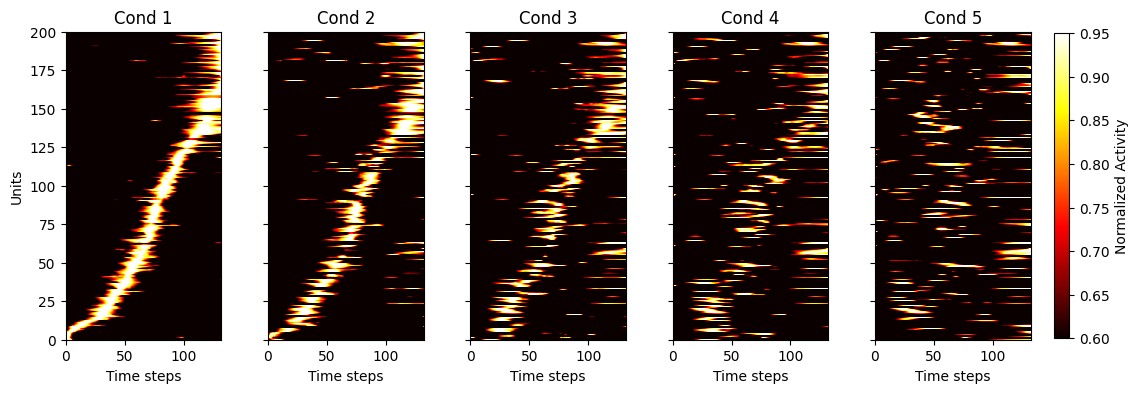

In [6]:
########
vmin=0.6
vmax=0.95
########
activations_c = tf.transpose(hidden_c, perm=[0, 2, 1]).numpy()   
fig, ax= plt.subplots(1, NUM_TRAJECTORIES, figsize=(15, 4))
Labels, average_act_c= plot_sorted_averaged_activations(ax, I, activations_c, vmin=vmin, vmax=vmax)


#### **Fig 4B : Heatmaps of The Constrained Network**

In [7]:
KWARGS_MODEL_PATH["alpha"]=1
MODEL_PATH= model_path( **KWARGS_MODEL_PATH )
print(MODEL_PATH)
########
KWARGS_LOAD_AND_PREDICT['I']= I
KWARGS_LOAD_AND_PREDICT['model_name']= MODEL_PATH
########
preds_p, hidden_p, model_p = load_and_predict(**KWARGS_LOAD_AND_PREDICT)

Models\Penalized_model_____Num_Trajectories_5_____Angle_20_____run_1_____Alpha_1.weights.h5


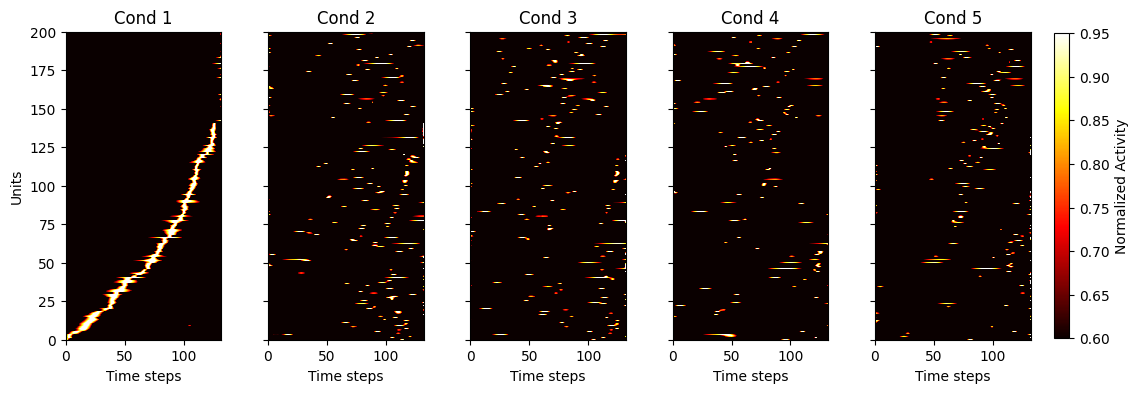

In [8]:
########
vmin=0.6
vmax=0.95
########
activations_p = tf.transpose(hidden_p, perm=[0, 2, 1]).numpy()   
fig, ax= plt.subplots(1, NUM_TRAJECTORIES, figsize=(15, 4))
Labels_p, average_act_p= plot_sorted_averaged_activations(ax, I, activations_p, vmin=vmin, vmax=vmax)

## **Plotting Predicted Trajectories**

#### **Original (Fig 3B) vs Predictions (Control : Fig 3D) & (Constrained : Fig 4C)**

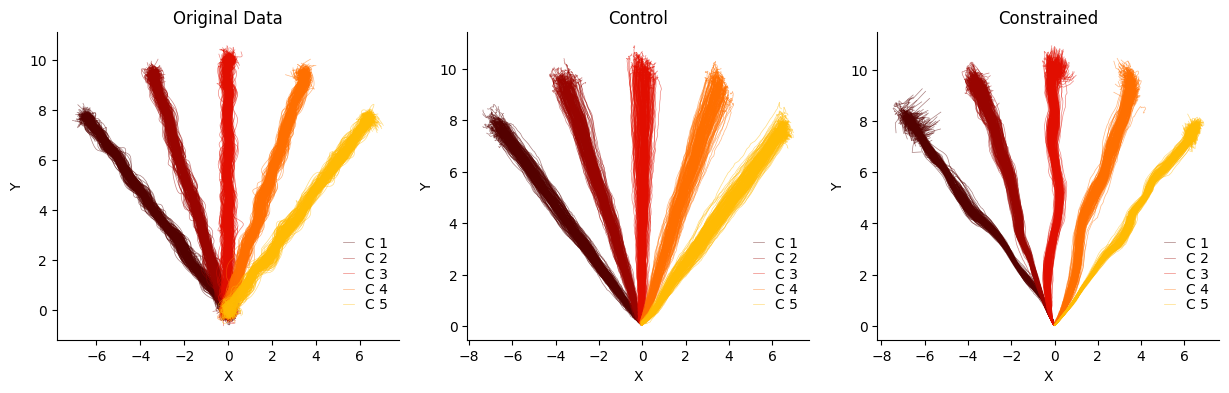

In [9]:
fig, axes= plt.subplots(1, 3, figsize=(15, 4))

######## Original Data
plot_trajectories_2d(axes[0], O, I, legend_kwargs={"loc": "lower left", "bbox_to_anchor": (0.8, 0.05)}, title="Original Data")    
axes[0].set_aspect('auto')  

######## Control Predictions 
plot_trajectories_2d(axes[1], preds_c, I, legend_kwargs={"loc": "lower left", "bbox_to_anchor": (0.8, 0.05)}, title="Control")    
axes[1].set_aspect('auto') 

######## Constrained Predictions 
plot_trajectories_2d(axes[2], preds_p, I, legend_kwargs={"loc": "lower left", "bbox_to_anchor": (0.8, 0.05)}, title="Constrained")    
axes[2].set_aspect('auto') 



## **Correlation**

#### **Representation Similarity: Control (Fig 3F) vs Constrained (Fig 4D - Left)**

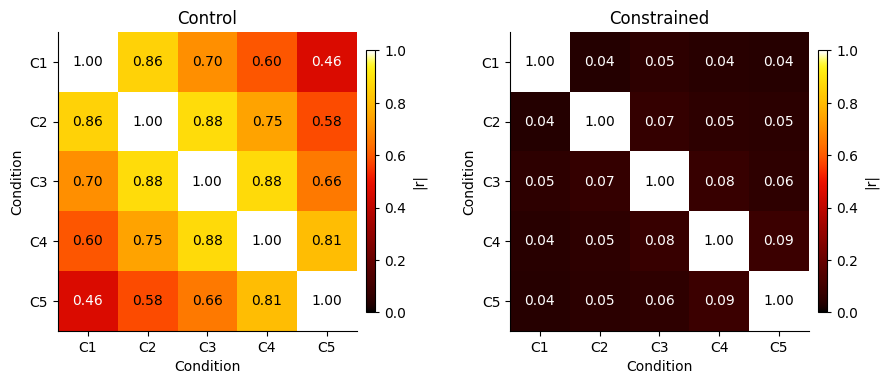

In [10]:
RSM_c = compute_rsm(np.asarray(average_act_c))
RSM_p = compute_rsm(np.asarray(average_act_p))

fig, axes= plt.subplots(1, 2, figsize=(10, 4), )
fig.subplots_adjust(wspace=0.4)

######## Control RSM 
plot_rsm(RSM_c, title="Control", ax=axes[0], cbar_label="|r|",)

######## Constrained RMS 
plot_rsm(RSM_p, title="Constrained", ax=axes[1], cbar_label="|r|",)


#### **Fig 4D - Right**

t = 207.69803987408056
p = 2.3554011032882288e-33


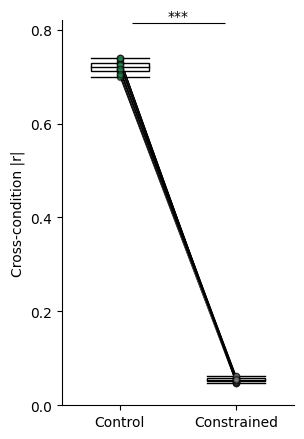

In [11]:

with open("METRICS_f(K, alphas).pkl", "rb") as f:
    METRICS = pickle.load(f)
########

data    = metric_matrix(METRICS, "Correlation", K=NUM_TRAJECTORIES, models=("Control", "Constrained 1"))
padding = 0.2 * (data.max() - data.min())
########

fig, ax = plt.subplots(figsize=(3, 5))
boxplot_with_lines(ax, data, xlabel=MODEL_LABELS, ylabel="Cross-condition |r|", colours=PAIR,
                   ymin=data.min() - padding, ymax=data.max() + padding,
                   use_legend=False)
ax.set_ylim(0, 0.82)
ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, ])
########

data1, data2 = data[0], data[1]
stat={}
stat['t'], stat['p'] = ttest_rel(data1, data2)
plot_siginficance_symbol_paired(ax,data,stat,height=0.1)
########

print(f"t = {stat['t']}")
print(f"p = {stat['p']}")

## **Task Phase Decoding**

#### **Fig 4E : Control vs Constrained**

In [12]:
with open("Decoding_10_runs.pkl", "rb") as f:
    all_runs = pickle.load(f)
#############

mae_values = {
    "Control":          collect_mae(all_runs, "control_cross",     "mae"),
    "Constrained":      collect_mae(all_runs, "constrained_cross", "mae"),
    "control shuf":     collect_mae(all_runs, "control_cross",     "mae_shuf"),
    "constrained shuf": collect_mae(all_runs, "constrained_cross", "mae_shuf"),
}

t = -30.28292296455752
p = 2.2842222303027183e-10


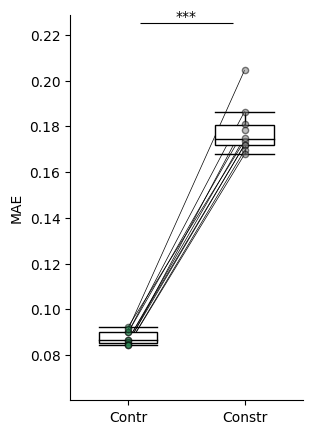

In [13]:
fig, ax = plt.subplots(figsize=(3, 5))


data = np.array([np.asarray(mae_values[k]) for k in MODEL_LABELS])
padding = 0.2 * (np.max(data) - np.min(data))

boxplot_with_lines(ax, data, xlabel=MODEL_LABELS_SHORT, ylabel="MAE", colours=PAIR,
                   ymin=np.min(data) - padding, ymax=np.max(data) + padding,
                   use_legend=False)
data1, data2 = data[0], data[1]
stat={}
stat['t'], stat['p'] = ttest_rel(data1, data2)
plot_siginficance_symbol_paired(ax,data,stat,height=0.1)
########

print(f"t = {stat['t']}")
print(f"p = {stat['p']}")

## **Behavioral Loss**

#### **Fig 4F : Asymptotic MSE + Loss Curves**

      bound  dof          pval
TOST  0.006   19  4.200541e-10


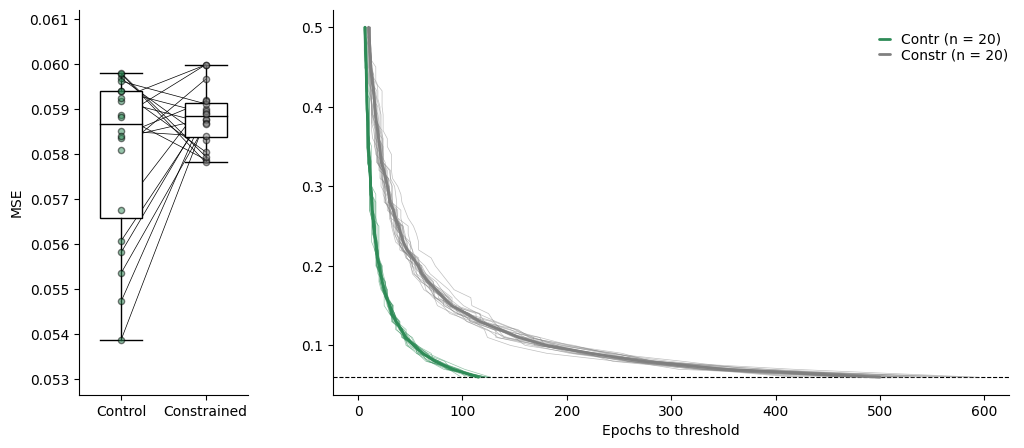

In [14]:
data    = metric_matrix(METRICS, "MSE", K=NUM_TRAJECTORIES, models=("Control", "Constrained 1"))
padding = 0.2 * (data.max() - data.min())
############

fig, axes = plt.subplots(1, 2, figsize=(12, 5),  gridspec_kw={"width_ratios": [1, 4]})
boxplot_with_lines(axes[0], data, xlabel=MODEL_LABELS, ylabel="MSE", colours=PAIR,
                   ymin=data.min() - padding, ymax=data.max() + padding,
                   use_legend=False)
############

Loss_1, Loss_2 = metric_curves(METRICS, "Behavior_Loss", K=NUM_TRAJECTORIES, models=("Control", "Constrained 1"))
Epochs_1, Epochs_2 = epochs_to_reach_thresholds(
    axes[1], LEVELS, Loss_1, Loss_2, xlabel=MODEL_LABELS_SHORT, colours=PAIR,
    ylabel="Epochs to threshold", xlabel_axis="",
    errorbar="sem", orient="loss-y", invert_loss=True,
    Loss_threshold=0.06, show_runs=True, use_legend=True, loc=[0.8, 0.85])
############


MSE_Threshold= 0.06
bound= MSE_Threshold * 0.1
data1, data2 = data[0], data[1]
############

result = pg.tost(data1, data2, bound=bound, paired=True)
print(result)

## **2 Way RM ANOVA**

#### **Fig 4G : Significant Bonfferroni Corrected paired t-tests**

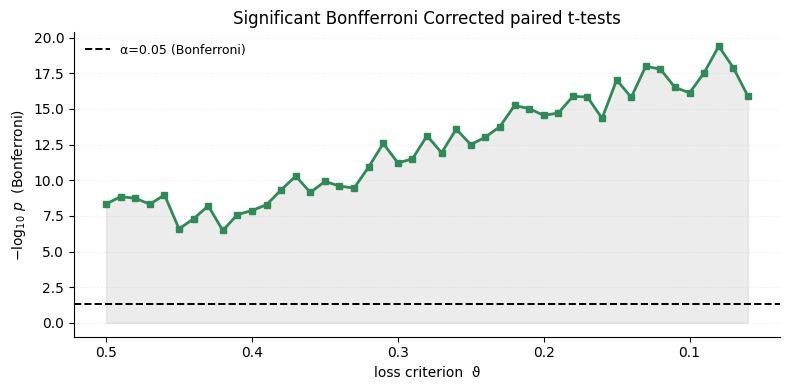

In [15]:
MODELS=["Control", "Constrained 1"]
N_TRAJECTORIES= f"K={NUM_TRAJECTORIES}"
FEATURE= "Behavior_Loss"


################################
Loss_1= list(METRICS[MODELS[0]][FEATURE][N_TRAJECTORIES].values())
Loss_2= list(METRICS[MODELS[1]][FEATURE][N_TRAJECTORIES].values())
Epochs_1= [np.arange(1, len(e)+1) for e in Loss_1 ] 
Epochs_2= [np.arange(1, len(e)+1) for e in Loss_2]
################################
Epochs_1, Epochs_2 = epochs_to_reach_thresholds(ax=None, Levels= LEVELS, Loss_1= Loss_1, Loss_2= Loss_2, 
                               colours=PAIR,
                               ylabel="Epochs to threshold",
                               xlabel_axis="Behavioural loss (MSE)",
                               ymin=None, ymax=None, use_legend=True,
                               errorbar="sem", orient="loss-x",
                               invert_loss=True, Loss_threshold=0.06,
                               show_runs=True, loc=[0.02, 0.85])
################################
Epochs_1 = np.array([epochs_to_reach(tr, LEVELS) for tr in Loss_1], dtype=float)
Epochs_2 = np.array([epochs_to_reach(tr, LEVELS) for tr in Loss_2], dtype=float)
################################ 2 ways RM ANOVA
Epochs= np.stack((Epochs_1, Epochs_2), axis=0)
N_Models, N_Runs, N_Levels= Epochs.shape
################################
records_paired= []
for m_idx, model in enumerate(['Stand', 'Constr']):
    for run in range(N_Runs):
        for l_idx, level in enumerate(LEVELS):
            row = {'model': model, 'level': level, 'epochs': Epochs[m_idx, run, l_idx]}
            records_paired.append({**row, 'subject': f'seed_{run}'})
################################
df_paired = pd.DataFrame(records_paired)
################################ Paired: true 2-way repeated measures ANOVA 
aov_paired = pg.rm_anova( data=df_paired, dv='epochs', within=['model', 'level'], subject='subject', correction=True )   # applies Greenhouse-Geisser when sphericity fails





################################ Post-Hoc pairwise t-tests
pvals_paired = []
for l_idx in range(len(LEVELS)):
    a = Epochs[0, :, l_idx]   # Model A, all 20 runs at this level
    b = Epochs[1, :, l_idx]   # Model B
    pvals_paired.append(stats.ttest_rel(a, b).pvalue)   # paired

################################ Bonferroni Corrected paired t-tests
pvals_bonf_paired = np.minimum(np.array(pvals_paired) * len(LEVELS), 1.0)
###############################




fig, ax = plt.subplots(figsize=(8,4))
colours=[COLORS[0], COLORS[-1], "k"]
###############################
L=np.asarray(LEVELS)
p=np.asarray(pvals_bonf_paired)
nlp=-np.log10(np.clip(p, 1e-300, 1))
bonf_alpha= 0.05
###############################
ax.plot(L, nlp, color=colours[0], lw=2, marker="s", ms=4, zorder=3)
ax.fill_between(L, 0, nlp, color=colours[1], alpha=0.15)
ax.axhline(-np.log10(bonf_alpha), color=colours[2], ls="--", lw=1.4, label=f"α={bonf_alpha} (Bonferroni)")
ax.invert_xaxis()
ax.set_xlabel("loss criterion  ϑ",) # fontsize=11)
ax.set_ylabel(r"$-\log_{10}\, p$  (Bonferroni)", ) # fontsize=11)
ax.set_title("Significant Bonfferroni Corrected paired t-tests",) # fontsize=11.5)
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", ls=":", alpha=0.25)
###############################
plt.tight_layout()
plt.show()



In [16]:
tvals_paired = []
pvals_paired = []
################################
for l_idx in range(len(LEVELS)):
    a = Epochs[0, :, l_idx]
    b = Epochs[1, :, l_idx]
    t_res = stats.ttest_rel(a, b)
    tvals_paired.append(t_res.statistic)
    pvals_paired.append(t_res.pvalue)

tvals_paired = np.array(tvals_paired)
pvals_paired = np.array(pvals_paired)
################################
dof = Epochs.shape[1] - 1 
print(f"k = {NUM_TRAJECTORIES} criteria, paired dof = {dof} (n = {Epochs.shape[1]} seeds)")
print(f"|t| range:  {np.abs(tvals_paired).min():.2f} to {np.abs(tvals_paired).max():.2f}")
print(f"raw p range:        {pvals_paired.min():.2e} to {pvals_paired.max():.2e}")
print(f"Bonferroni p range: {pvals_bonf_paired.min():.2e} to {pvals_bonf_paired.max():.2e}")
print(f"significant at every criterion (max corrected p < 0.05)? {pvals_bonf_paired.max() < 0.05}")
################################
print('\n')
row_model = aov_paired[aov_paired['Source'] == 'model']
row_inter = aov_paired[aov_paired['Source'] == 'model * level']
F_model, p_model = row_model['F'].values[0], row_model['p-GG-corr'].values[0]
F_inter, p_inter = row_inter['F'].values[0], row_inter['p-GG-corr'].values[0]
print(f"Main effect (model):        F = {F_model:.2f}, p = {p_model:.3e}")
print(f"Interaction (model×level):  F = {F_inter:.2f}, p = {p_inter:.3e}")
################################
print('\n')
ddof1_m, ddof2_m = row_model['ddof1'].values[0], row_model['ddof2'].values[0]
ddof1_i, ddof2_i = row_inter['ddof1'].values[0], row_inter['ddof2'].values[0]
print(f"Main effect df: ({ddof1_m}, {ddof2_m})")
print(f"Interaction df: ({ddof1_i}, {ddof2_i})")

k = 5 criteria, paired dof = 19 (n = 20 seeds)
|t| range:  9.79 to 50.90
raw p range:        8.88e-22 to 7.40e-09
Bonferroni p range: 4.00e-20 to 3.33e-07
significant at every criterion (max corrected p < 0.05)? True


Main effect (model):        F = 2677.09, p = 6.523e-22
Interaction (model×level):  F = 1069.01, p = 1.482e-36


Main effect df: (1, 19)
Interaction df: (44, 836)


## **Scalling Over Number Of Trajectories**

#### **Fig 4H : Epochs = f(K)** ##

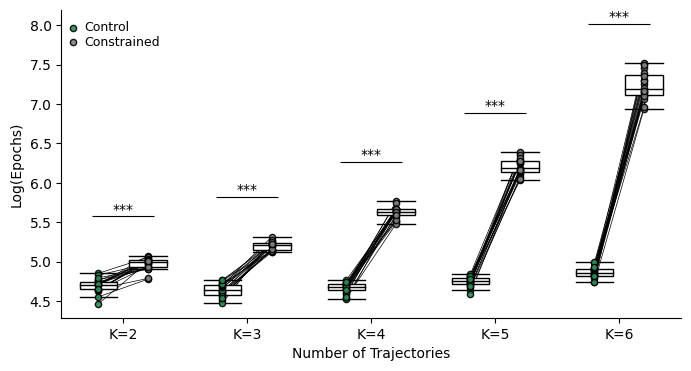

In [17]:


fig, ax = plt.subplots(figsize=(8,4))
###############################
FEATURE= "Epochs"
Ks= [f"K={k}" for k in range(2, 7)]
###############################
a= np.log(np.array([list(METRICS["Control"][FEATURE][i].values()) for i in Ks]).T)
b= np.log(np.array([list(METRICS["Constrained 1"][FEATURE][i].values()) for i in Ks]).T)
data= [a, b]
###############################
res = plot_box_comparison_multiple(
        data=data,
        alpha_values=Ks,
        model_labels=["Control", "Constrained"],
        ylabel="Log(Epochs)", xlabel=r"Number of Trajectories", title="",
        colours=PAIR,
        alpha_palette=None,       # per-alpha colors, used only when M == 1
        ax=ax, figsize=None,
        box_width=0.3, dodge=0.40, jitter=0.00,
        ms=20, box_facecolor="white", seed=1,
        ymin=None, ymax=None,
        use_legend=True, connect=True,
        show_significance= True,
        y_offset_significance=0.5,
        legend_args= { "loc": "upper left","bbox_to_anchor": (0., 1),"fontsize": 9 }
    )


In [18]:
FEATURE= "Epochs"
a= np.array([list(METRICS["Control"][FEATURE][i].values()) for i in Ks]).T
b= np.array([list(METRICS["Constrained 1"][FEATURE][i].values()) for i in Ks]).T
data= [a, b]

for i in range(data[0].shape[1]):
    print('\nK=', i+2, '\n-----')
    a=data[0][:, i]
    b=data[1][:, i]
    # print('     Control     :', a[:5])
    # print('     Constrained :', b[:5])
    stat={}
    stat['t'], stat['p'] = ttest_rel(a, b)
    plot_siginficance_symbol_paired(ax,[a, b],stat,height=0.1)
    print(f"     t = {stat['t']}")
    print(f"     p = {stat['p']}")


K= 2 
-----
     t = -11.593424517067875
     p = 4.626997715092741e-10

K= 3 
-----
     t = -24.793111081984442
     p = 6.210110194343146e-16

K= 4 
-----
     t = -36.78510510561576
     p = 4.003608918711313e-19

K= 5 
-----
     t = -33.122152743292
     p = 2.852904310870281e-18

K= 6 
-----
     t = -22.68062888675245
     p = 3.199171869041919e-15


## **Extended Data Fig 4**

## **Dimensionality**

#### **ED Fig 4C : Participation Ratio & Cumulative Variance**

t = -34.43895863384641
p = 1.3759755439603737e-18


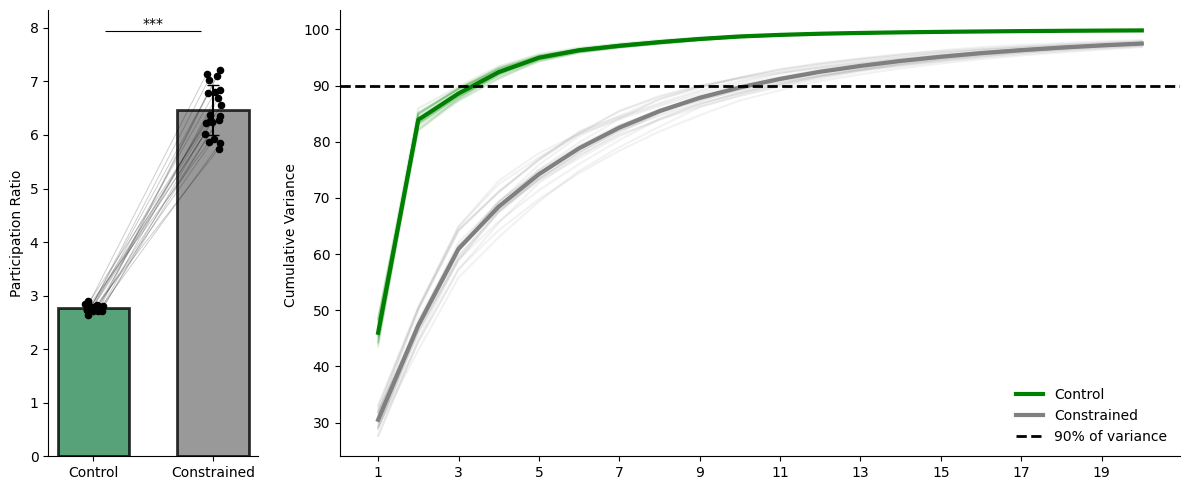

In [19]:
with open("dimensionality.pkl", "rb") as f:
    dimensionality = pickle.load(f)
#########################


labels = dimensionality.keys()
#########################
means = []
stds = []
#########################
for name in labels:
    values = np.array(list(dimensionality[name]["participation_ratio"].values()))
    means.append(np.mean(values))
    stds.append(np.std(values, ddof=1))
#########################



fig, axes= plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 4]})
fig.subplots_adjust(wspace=0.6)
x = np.arange(1, len(labels)+1)
ax= axes[0]
ax.bar( x, means, yerr=stds, capsize=4, color=PAIR,
    edgecolor="black", linewidth=2, alpha=0.8, width=0.6,)
#########################
data=[]
for i, name in enumerate(labels):
    values = np.array(list(dimensionality[name]["participation_ratio"].values()))
    jitter =  np.random.uniform(-0.08, 0.08, len(values))
    data.append(values)
    ax.scatter(x[i] + jitter, values, color="black", s=20, zorder=3)
#########################
for j in range(len(data[0])):
    ax.plot( [x[0] + jitter[j], x[1] + jitter[j]],
        [data[0][j], data[1][j]], color="black",
        lw=0.7, alpha=0.2, zorder=2 )
#########################
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylabel("Participation Ratio")
#########################
data1, data2 = data[0], data[1]
stat={}
stat['t'], stat['p'] = ttest_rel(data1, data2)
plot_siginficance_symbol_paired(ax,data,stat,height=0.1)
print(f"t = {stat['t']}")
print(f"p = {stat['p']}")






ctrl_var= np.array(list(dimensionality["Control"]["cumulative_variance"].values()))
constr_var= np.array(list(dimensionality["Constrained"]["cumulative_variance"].values()))
##################
ctrl_mean = np.mean(ctrl_var, axis=0)
ctrl_sem = np.std(ctrl_var, axis=0, ddof=1) / np.sqrt(ctrl_var.shape[0])
##################
constr_mean = np.mean(constr_var, axis=0)
constr_sem = np.std(constr_var, axis=0, ddof=1) / np.sqrt(constr_var.shape[0])
##################
x = np.arange(1, ctrl_var.shape[1]+1)
##################



ax= axes[1]
ax.plot(x, ctrl_mean, color='green', label="Control", lw=3)
for v in ctrl_var:
    ax.plot(x, v, color='green' , alpha=0.1)
##################
ax.plot(x, constr_mean, color='grey', label="Constrained", lw=3)
for v in constr_var:
    ax.plot(x, v, color='grey' , alpha=0.1)
##################
ax.set_xticks([1, 3, 5, 7, 9, 11, 13, 15, 17, 19 ])
ax.axhline(y=90, color="k", lw=2, linestyle="--", label="90% of variance")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)
ax.set_ylabel("Cumulative Variance ")


#########################
plt.tight_layout()
plt.show()

In [20]:
RUNS = [run for run in range(1, 21)]
###################################
THRESH= 90
###################################
ctrl_n = []
constr_n = []
for s in RUNS:
    ctrl_n.append(n_comp_90(dimensionality["Control"]["cumulative_variance"][s]))
    constr_n.append(n_comp_90(dimensionality["Constrained"]["cumulative_variance"][s]))
###################################
ctrl_n = np.array(ctrl_n, dtype=float)
constr_n = np.array(constr_n, dtype=float)
###################################

for name, n in [("Control", ctrl_n), ("Constrained", constr_n)]:
    n_missing = np.sum(np.isnan(n))
    if n_missing > 0:
        print(f"WARNING: {name}: {int(n_missing)} seed(s) never reach {THRESH}% "
              f"within {len(ctrl_n)} stored components")
    ###################################
    mean = np.nanmean(n)
    sd = np.nanstd(n, ddof=1)
    median = np.nanmedian(n)
    q1 = np.nanpercentile(n, 25)
    q3 = np.nanpercentile(n, 75)
    n_valid = np.sum(~np.isnan(n))
    ###################################
    print(f"{name}: {mean:.2f} ± {sd:.2f} (mean ± SD), "
          f"median {median:.1f} [{q1:.1f}–{q3:.1f}], n = {n_valid}")

Control: 4.00 ± 0.00 (mean ± SD), median 4.0 [4.0–4.0], n = 20
Constrained: 10.80 ± 0.70 (mean ± SD), median 11.0 [10.0–11.0], n = 20


## **Weights**

#### **ED Fig 4A : weight distribution & correspondance**

In [21]:
#########################
KWARGS_MODEL_PATH["run"]= 1
KWARGS_MODEL_PATH["alpha"]= 0
MODEL_PATH = model_path(**KWARGS_MODEL_PATH)
preds, hidden_activity, control_model = load_and_predict( **{**KWARGS_LOAD_AND_PREDICT, "I": I, "model_name": MODEL_PATH} )
#########################
KWARGS_MODEL_PATH["alpha"]= 1
MODEL_PATH = model_path(**KWARGS_MODEL_PATH)
preds, hidden_activity, constrained_model = load_and_predict( **{**KWARGS_LOAD_AND_PREDICT, "I": I, "model_name": MODEL_PATH} )
#########################


#########################
W_c = (control_model.w_intra * control_model.mask).numpy()
W_p = (constrained_model.w_intra * constrained_model.mask).numpy()
#########################
mask_c = control_model.mask.numpy() > 0
mask_p = constrained_model.mask.numpy() > 0
same_mask = np.array_equal(mask_c, mask_p)
#########################
aw_c = W_c[mask_c]      
aw_p = W_p[mask_c]      
#########################
ks_stat, ks_p = stats.ks_2samp(aw_c, aw_p)                       
row_norms_c = np.linalg.norm(W_c, axis=1)                        
row_norms_p = np.linalg.norm(W_p, axis=1)                        
t_stat, t_p = stats.ttest_rel(row_norms_c, row_norms_p)
#########################
print(f"Weight comparison: Control vs. Constrained")
print("-" * 50)
print(f"Same connectivity mask       : {same_mask}")
print(f"Active connections           : {aw_c.size}")
print(f"Control weights     mean/sd  : {aw_c.mean():+.5f} / {aw_c.std():.5f}")
print(f"Constrained weights mean/sd  : {aw_p.mean():+.5f} / {aw_p.std():.5f}")
print(f"Weight distribution (KS test): D = {ks_stat:.3f}, p = {ks_p:.3f}")
print(f"Per-unit input norm (paired t-test): t = {t_stat:.3f}, p = {t_p:.3f}")


Weight comparison: Control vs. Constrained
--------------------------------------------------
Same connectivity mask       : True
Active connections           : 16000
Control weights     mean/sd  : -0.00023 / 0.00574
Constrained weights mean/sd  : +0.00006 / 0.00700
Weight distribution (KS test): D = 0.039, p = 0.000
Per-unit input norm (paired t-test): t = -18.856, p = 0.000


In [22]:
r_w, p_r = stats.pearsonr(aw_c, aw_p)   # how tightly weights track each other
print(f"weight correspondence: Pearson r = {r_w:.3f}, p = {p_r:.3g}")
# print(ks_stat, ks_p)

from statsmodels.stats.weightstats import ttost_paired
# aw_c, aw_p: active weights, same connections, control vs constrained (paired by synapse)
pooled_sd = np.std(np.concatenate([aw_c, aw_p]), ddof=1)
bound = 0.10 * pooled_sd     # equivalence margin = 10% of the weights' own SD
pval, t1, t2 = ttost_paired(aw_c, aw_p, low=-bound, upp=bound)

print(f"bound = ±{bound:.5f} (10% of pooled SD = {pooled_sd:.5f})")
print(f"dof = {len(aw_c) - 1}")
print(f"TOST p = {pval:.3g}")
print(f"lower one-sided: t = {t1[0]:.2f}, p = {t1[1]:.3g}")
print(f"upper one-sided: t = {t2[0]:.2f}, p = {t2[1]:.3g}")

weight correspondence: Pearson r = 0.800, p = 0
bound = ±0.00064 (10% of pooled SD = 0.00640)
dof = 15999
TOST p = 1.6e-25
lower one-sided: t = 10.39, p = 1.6e-25
upper one-sided: t = -28.13, p = 2.45e-170


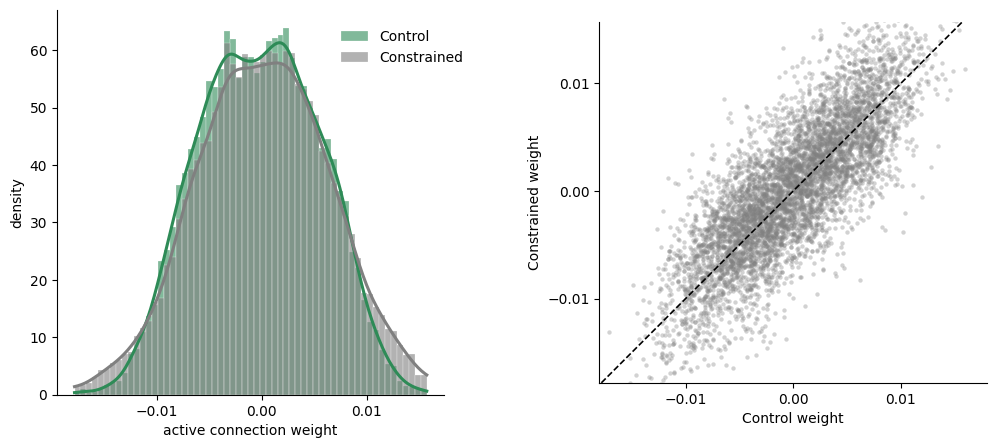

In [23]:
fig, axes= plt.subplots(1, 2, figsize=(12, 5), )
fig.subplots_adjust(wspace=0.4)
################
ax= axes[0]
ax.spines[['top', 'right']].set_visible(False)
plot_weight_distribution(ax, 
                         aw_c, 
                         aw_p, 
                         ks_stat, 
                         ks_p, 
                         colors= [COLORS[0], COLORS[-1]],  
                         legend_kwarg = {"loc": "upper left", 
                                         "bbox_to_anchor": (0.7, 0.98),})
ax.set_xticks([-0.01, 0, 0.01])
################

ax= axes[1]
ax.spines[['top', 'right']].set_visible(False)
################
plot_weight_correspondence(
            ax=ax,
            data=[aw_c, aw_p],
            xlabel="Control weight",
            ylabel="Constrained weight",
            title="",
            colour="gray",
            sample_size=6000,
            seed=0,)
ax.set_xlim(-0.018, 0.018)
ax.set_yticks([-0.01, 0, 0.01])
ax.set_xticks([-0.01, 0, 0.01])
################
plt.show()
################

#### **ED Fig 4B : PCA Projections**

Models\Penalized_model_____Num_Trajectories_5_____Angle_20_____run_1_____Alpha_0.weights.h5
Models\Penalized_model_____Num_Trajectories_5_____Angle_20_____run_1_____Alpha_1.weights.h5
procrustes disparity = 0.3818


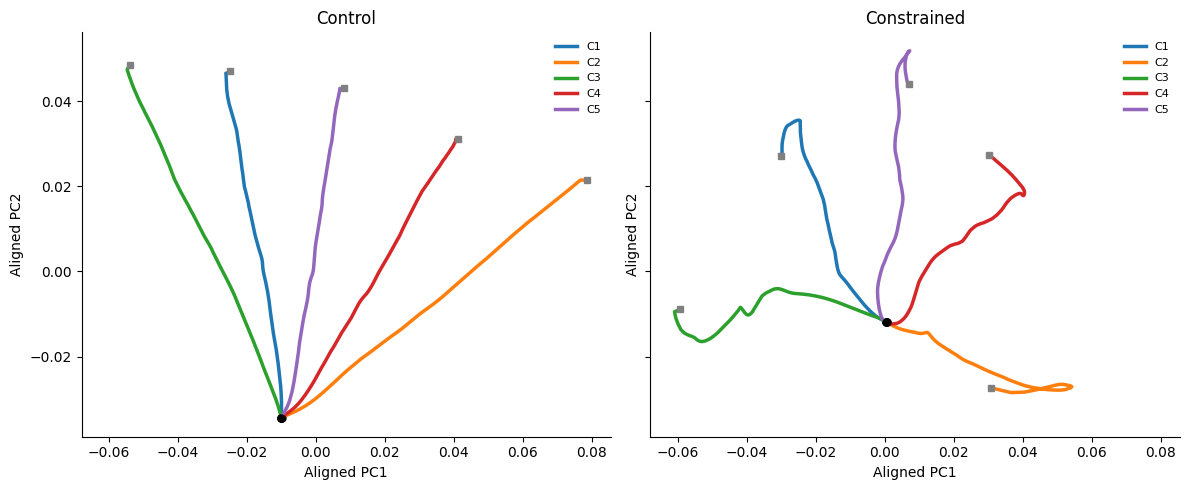

In [24]:
I= I[:BATCH_SIZE]
models = {}
hidden = {}
activations = {}
pca_models = {}                
pca_3d = {}  
#########################
run= 1
#########################
for name, alpha in zip( ["Control", "Constrained"], [0, 1]):
    ########
    KWARGS_MODEL_PATH["alpha"]=alpha
    KWARGS_MODEL_PATH["run"]=run
    MODEL_PATH= model_path( **KWARGS_MODEL_PATH )
    print(MODEL_PATH)
    ########
    KWARGS_LOAD_AND_PREDICT['I']= I[:BATCH_SIZE]
    KWARGS_LOAD_AND_PREDICT['model_name']= MODEL_PATH
    ########
    preds, hidden_activity, model = load_and_predict(**KWARGS_LOAD_AND_PREDICT)
    act= average_conditions(hidden_activity, I) 
    ########
    models[name] = model
    hidden[name] = hidden_activity
    activations[name] = act
    #########################
    X = flatten_for_pca(act)
    pca = PCA()
    pca.fit(X)
    pca_models[name] = pca
    pca_3d[name] = pca.transform(X)[:, :3].reshape(NUM_TRAJECTORIES, NUM_STEPS, 3)
#########################
titles = list(pca_3d.keys())
projections = list(pca_3d.values())
#########################



#########################
X_ = projections[0][:,:,:2]
Y_ = projections[1][:,:,:2]
#########################
X = X_.reshape(-1, 2)
Y = Y_.reshape(-1, 2)
X_aligned, Y_aligned, disparity = procrustes(X, Y)
print(f"procrustes disparity = {disparity:.4f}")
#########################
X_aligned = X_aligned.reshape(NUM_TRAJECTORIES, NUM_STEPS, 2)
Y_aligned = Y_aligned.reshape(NUM_TRAJECTORIES, NUM_STEPS, 2)




#########################
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
#########################
axes[0].spines[['top', 'right']].set_visible(False)
for i in range(NUM_TRAJECTORIES):
    axes[0].plot( X_aligned[i, :, 0], X_aligned[i, :, 1], lw=2.5, label=f"C{i+1}" )
    axes[0].plot( X_aligned[i, 0, 0], X_aligned[i, 0, 1], 'o', ms=5, color='k' )
    axes[0].plot( X_aligned[i, -1, 0], X_aligned[i, -1, 1], 's', ms=5, color='grey' )
axes[0].set_title("Control")
axes[0].set_xlabel("Aligned PC1")
axes[0].set_ylabel("Aligned PC2")
axes[0].legend(frameon=False, fontsize=8)

#########################
axes[1].spines[['top', 'right']].set_visible(False)
for i in range(NUM_TRAJECTORIES):
    axes[1].plot( Y_aligned[i, :, 0], Y_aligned[i, :, 1], lw=2.5, label=f"C{i+1}" )
    axes[1].plot( Y_aligned[i, 0, 0], Y_aligned[i, 0, 1], 'o', ms=5, color='k' )
    axes[1].plot( Y_aligned[i, -1, 0], Y_aligned[i, -1, 1], 's', ms=5, color='grey' )
axes[1].set_title("Constrained")
axes[1].set_xlabel("Aligned PC1")
axes[1].set_ylabel("Aligned PC2")
axes[1].legend(frameon=False, fontsize=8)

plt.tight_layout()
plt.show()

#### **ED Fig 4D : Mean activity**

=== Overall mean activity (averaged across 5 conditions) ===
control     1.3399 ± 0.0383
constrained 0.5474 ± 0.0542
t=50.99, p=8.61e-22, dof=19


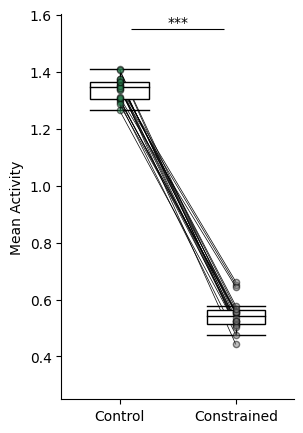

In [25]:
I= I[:BATCH_SIZE]
mean_activations = { "Control": {}, "Constrained": {} }
#########################
for run in RUNS:
    #########################
    for name, alpha in zip( ["Control", "Constrained"], [0, 1]):
        ########
        KWARGS_MODEL_PATH["alpha"]=alpha
        KWARGS_MODEL_PATH["run"]=run
        MODEL_PATH= model_path( **KWARGS_MODEL_PATH )
        ########
        KWARGS_LOAD_AND_PREDICT['I']= I[:BATCH_SIZE]
        KWARGS_LOAD_AND_PREDICT['model_name']= MODEL_PATH
        ########
        preds, hidden_activity, model = load_and_predict(**KWARGS_LOAD_AND_PREDICT)
        act= average_conditions(hidden_activity, I) 
        ########
        mean_activations[name][run]= act.mean()

data_1 = list(mean_activations["Control"].values())
data_2 = list(mean_activations["Constrained"].values())
##################
data = np.array([data_1, data_2])
##################
labels = ['Control', 'Constrained']
##################
padding = 0.2 * (np.max(data) - np.min(data))
##################



##################
fig, ax= plt.subplots(figsize=(3, 5))
boxplot_with_lines(ax, data, xlabel=labels, ylabel="Mean Activity", colours=PAIR,
                   ymin=np.min(data) - padding, ymax=np.max(data) + padding,
                   use_legend=False)
##################
data1, data2 = data[0], data[1]
stat={}
stat['t'], stat['p'] = ttest_rel(data1, data2)
plot_siginficance_symbol_paired(ax,data,stat,height=0.1)
##################
print("=== Overall mean activity (averaged across 5 conditions) ===")
print(f"control     { np.mean(data_1):.4f} ± { np.std(data_1):.4f}")
print(f"constrained { np.mean(data_2):.4f} ± { np.std(data_2):.4f}")
print(f"t={stat['t']:.2f}, p={stat['p']:.3g}, dof={len(data_1)-1}")



## **Extended Data Fig 5 : Control Tests**

In [26]:
######################
##### Fixed Size #####
######################
with open("METRICS_Fixed_Size.pkl", "rb") as f:
    METRICS = pickle.load(f)
#####
Corr_Control_1, Corr_Constrained_1=[], []
E_Control_1, E_Constrained_1=[], []
#####
for k in KS:
    #####
    Corr_Control_1.append(list(METRICS["Control"]["Correlation"][f"K={k}"].values()))
    Corr_Constrained_1.append(list(METRICS["Constrained"]["Correlation"][f"K={k}"].values()))
    #####
    E_Control_1.append(list(METRICS["Control"]["Epochs"][f"K={k}"].values()))
    E_Constrained_1.append(list(METRICS["Constrained"]["Epochs"][f"K={k}"].values()))






#######################
##### Angle Sweep #####
#######################
with open("METRICS_f(angle)_K=cste.pkl", "rb") as f:
    METRICS = pickle.load(f)
#####
Corr_Control_2, Corr_Constrained_2=[], []
E_Control_2, E_Constrained_2=[], []
#####
MODEL_ALPHAS = { "Control": 0, "Constrained 1": 1 }
N_runs= 10
#####
for angle in ANGLES:
    #####
    Corr_Control_2.append(list(METRICS["Control"]["Correlation"][f"angle={angle}"].values()))
    Corr_Constrained_2.append(list(METRICS["Constrained 1"]["Correlation"][f"angle={angle}"].values()))
    #####
    E_Control_2.append(list(METRICS["Control"]["Epochs"][f"angle={angle}"].values()))
    E_Constrained_2.append(list(METRICS["Constrained 1"]["Epochs"][f"angle={angle}"].values()))

#### **ED Fig 5A : Fixed Data Size and K Sweep**

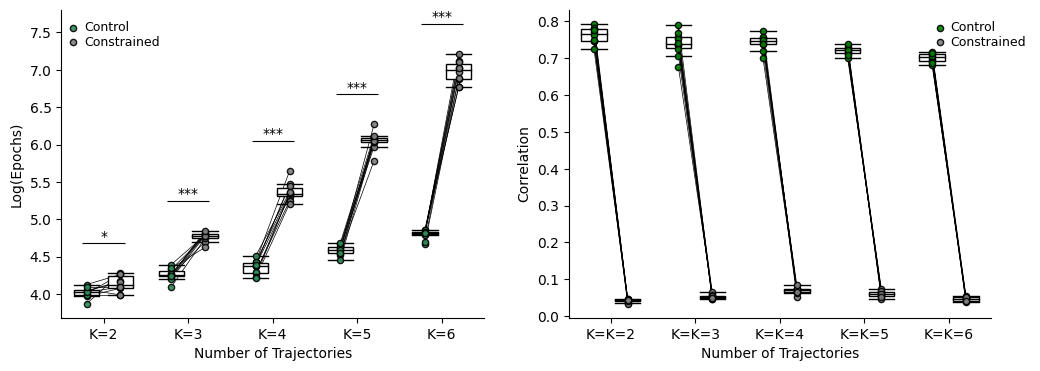

In [27]:
fig, axes= plt.subplots(1, 2, figsize=(12, 4))
fig.subplots_adjust(wspace=0.2)


ax= axes[0]
data= np.log( np.array([ np.array(E_Control_1).T,  np.array(E_Constrained_1).T ]))
res = plot_box_comparison_multiple(
        data=data,
        alpha_values=[f"K={k}" for k in KS],
        model_labels=["Control", "Constrained"],
        ylabel="Log(Epochs)", xlabel=r"Number of Trajectories", title="",
        colours=(COLORS[0], COLORS[-1]),
        alpha_palette=None,       # per-alpha colors, used only when M == 1
        ax=ax, figsize=None,
        box_width=0.3, dodge=0.40, jitter=0.00,
        ms=20, box_facecolor="white", seed=1,
        ymin=None, ymax=None,
        use_legend=True, connect=True,
        show_significance= True,
        y_offset_significance=0.4,
        legend_args= { "loc": "upper left", "bbox_to_anchor": (0., 1), "fontsize": 9 }
    )


ax= axes[1]
data= [ np.array(Corr_Control_1).T,  np.array(Corr_Constrained_1).T ]
res = plot_box_comparison_multiple(
        data=data,
        alpha_values=[f"K={k}" for k in Ks],
        model_labels=["Control", "Constrained"],
        ylabel="Correlation", xlabel=r"Number of Trajectories", title="",
        colours=("green", "gray"),
        alpha_palette=None,       # per-alpha colors, used only when M == 1
        ax=ax, figsize=None,
        box_width=0.3, dodge=0.40, jitter=0.00,
        ms=20, box_facecolor="white", seed=1,
        ymin=None, ymax=None,
        use_legend=True, connect=True,
    )

#### **ED Fig 5B : Angle Sweep**

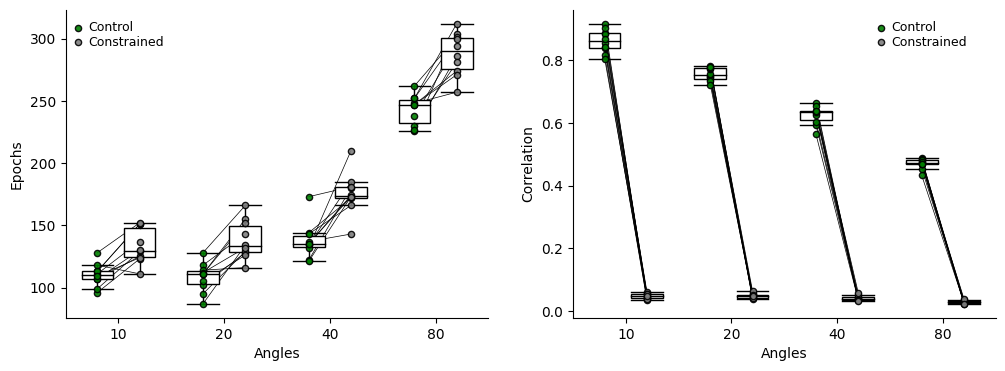

In [28]:
fig, axes= plt.subplots(1, 2, figsize=(12, 4))
fig.subplots_adjust(wspace=0.2)

ax= axes[0]
data= [ np.array(E_Control_2).T,  np.array(E_Constrained_2).T ]
res = plot_box_comparison_multiple(
        data=data,
        alpha_values=ANGLES,
        model_labels=["Control", "Constrained"],
        ylabel="Epochs", xlabel=r"Angles", title="",
        colours=("green", "gray"),
        alpha_palette=None,       # per-alpha colors, used only when M == 1
        ax=ax, figsize=None,
        box_width=0.3, dodge=0.40, jitter=0.00,
        ms=20, box_facecolor="white", seed=1,
        ymin=None, ymax=None,
        use_legend=True, connect=True,
         legend_args= { "loc": "upper left","bbox_to_anchor": (0., 1),"fontsize": 9 }
    )


ax= axes[1]
data= [ np.array(Corr_Control_2).T,  np.array(Corr_Constrained_2).T ]
res = plot_box_comparison_multiple(
        data=data,
        alpha_values=ANGLES,
        model_labels=["Control", "Constrained"],
        ylabel="Correlation", xlabel=r"Angles", title="",
        colours=("green", "gray"),
        alpha_palette=None,       # per-alpha colors, used only when M == 1
        ax=ax, figsize=None,
        box_width=0.3, dodge=0.40, jitter=0.00,
        ms=20, box_facecolor="white", seed=1,
        ymin=None, ymax=None,
        use_legend=True, connect=True, legend_args= { "loc": "upper left","bbox_to_anchor": (0.7, 1),"fontsize": 9 }
    )

#### **ED Fig 5C : Alpha Sweep**

K=2: F=25.41, p=3.48e-16
K=3: F=125.36, p=3.05e-40
K=4: F=379.07, p=4.17e-61
K=5: F=377.60, p=4.97e-61
K=6: F=300.52, p=1.4e-56
K=2: F=8212.11, p=1.46e-123
K=3: F=4460.74, p=5.15e-111
K=4: F=13503.79, p=8.37e-134
K=5: F=16476.78, p=6.66e-138
K=6: F=23896.65, p=1.45e-145


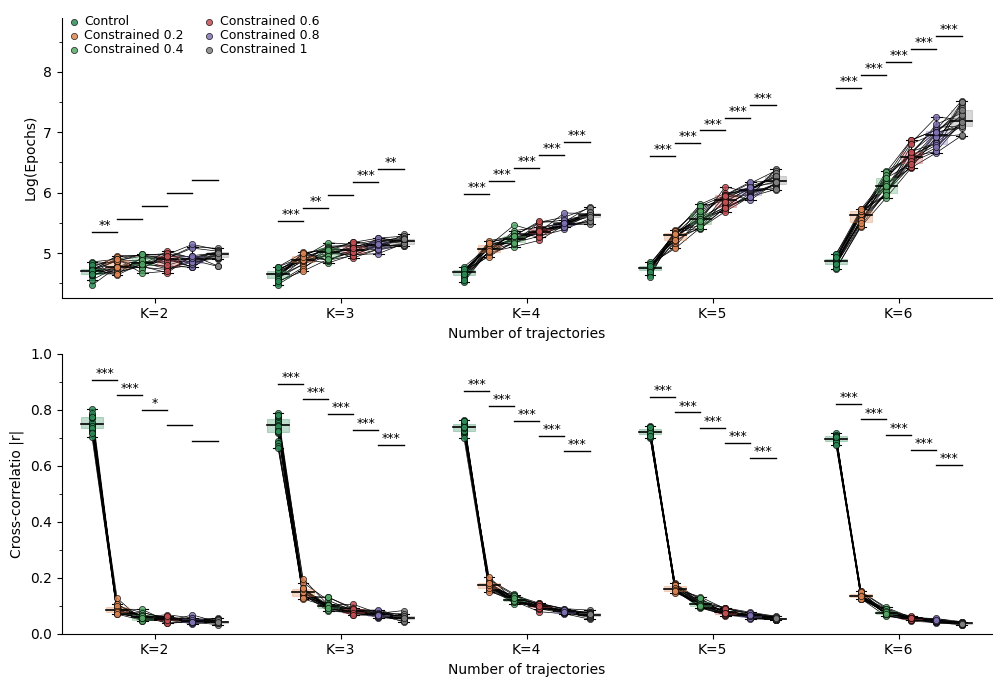

In [29]:

with open("METRICS_f(K, alphas).pkl", "rb") as f:
    METRICS = pickle.load(f)

LABELS = list(METRICS.keys())  # Control, Constrained 0.2, ..., Constrained 1
data = [epochs_array(METRICS, m, KS, N_runs) for m in LABELS]
adjacent_pvals = [adjacent_p_for_K(METRICS, K, LABELS, feature='Epochs') for K in KS]
    
data_by_alpha = []
for label in LABELS:
    arr = np.array([
        [np.log(METRICS[label]["Epochs"][f"K={K}"][run]) for K in KS]
        for run in range(1, 21)
    ])  
    data_by_alpha.append(arr)



fig, axes= plt.subplots(2, 1, figsize=(12, 8))
fig.subplots_adjust(hspace=0.2)
ax= axes[0]
plot_box_comparison_multiple_1(
    data_by_alpha,
    alpha_values=[f"K={KS[i]}" for i in range(len(KS))],
    model_labels=LABELS,
    colors=COLORS,
    xlabel="Number of trajectories", ylabel="Log(Epochs)",
    dodge=0.135, box_width=0.115, jitter=0.0, ms=20,
    connect=True, legend=True,
    annot="stars",
    adjacent_pvals= adjacent_pvals,
    legend_args= { "loc": "upper left", "bbox_to_anchor": (0., 1.05), "fontsize": 9 , 'ncol':2},
    ax=ax, y_offset_significance= 0
)




data = [correlation_array(METRICS, m, KS, N_runs) for m in LABELS]
adjacent_pvals = [adjacent_p_for_K(METRICS, K, LABELS, feature='Correlation') for K in KS]
data_by_alpha = []
for label in LABELS:
    arr = np.array([
        [METRICS[label]["Correlation"][f"K={K}"][run] for K in KS]
        for run in range(1, 21)
    ])  
    data_by_alpha.append(arr)


ax= axes[1]
plot_box_comparison_multiple_1(
    data_by_alpha,
    alpha_values=[f"K={KS[i]}" for i in range(len(KS))],
    model_labels=LABELS,
    colors=COLORS, 
    xlabel="Number of trajectories", ylabel="Cross-correlatio |r|",
    dodge=0.135, box_width=0.115, jitter=0.0, ms=20,
    connect=True, legend=False,
    annot="stars",
    adjacent_pvals= adjacent_pvals,
    legend_args= { "loc": "upper left", "bbox_to_anchor": (0.6, 1.05), "fontsize": 9 , 'ncol':2}, 
    ax=ax, y_offset_significance=0.05, DESCENDANT= True
)
ax.set_ylim(0, 1)
ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1])
plt.show()